# Assignment 3.3: Histogram Equalization (CDF)

### 1. Import Libraries


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 2. Load and Display the Image


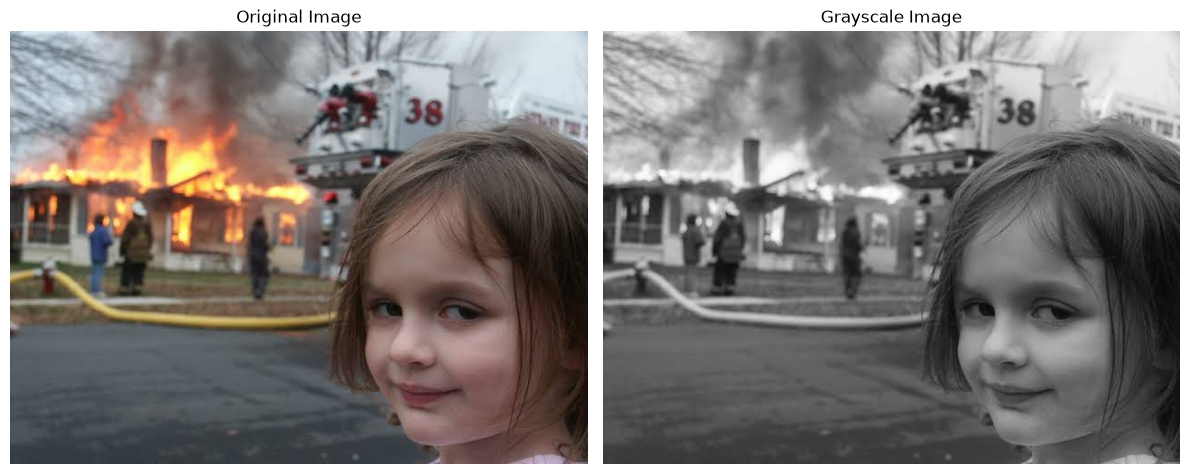

In [2]:
image_path = "../assets/input/sample.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### 3. Generate the Histogram and CDF


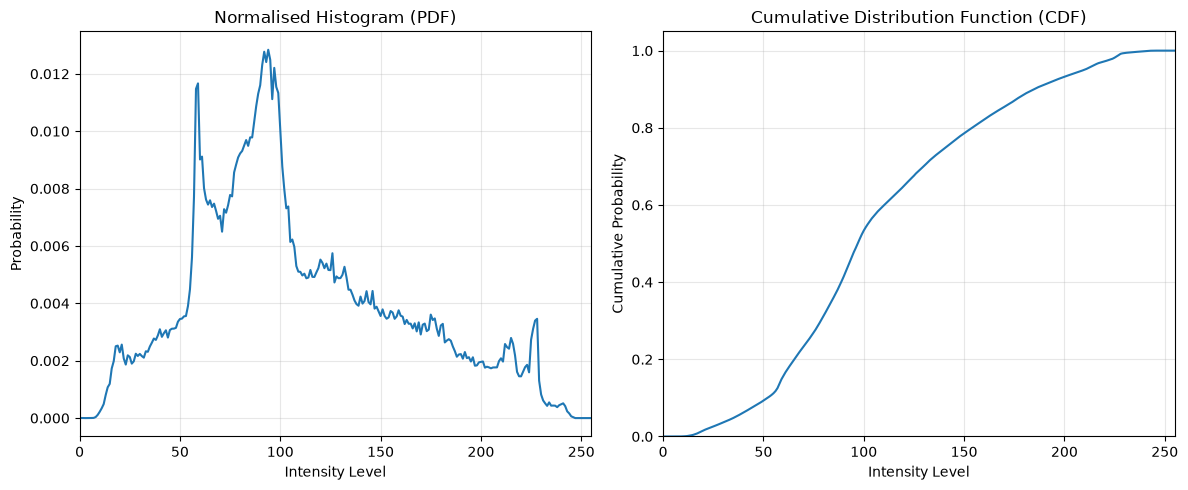

In [3]:
# Calculate the grayscale histogram
histogram = cv2.calcHist([gray_image], [0], None, [256], [0, 256]).flatten()

# Calculate the normalised histogram (PDF)
pdf = histogram / gray_image.size

# Calculate the cumulative distribution function (CDF)
cdf = np.cumsum(pdf)

intensity_levels = np.arange(256)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(intensity_levels, pdf)
plt.title("Normalised Histogram (PDF)")
plt.xlabel("Intensity Level")
plt.ylabel("Probability")
plt.xlim(0, 255)
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(intensity_levels, cdf)
plt.title("Cumulative Distribution Function (CDF)")
plt.xlabel("Intensity Level")
plt.ylabel("Cumulative Probability")
plt.xlim(0, 255)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4. Perform Histogram Equalization Using CDF


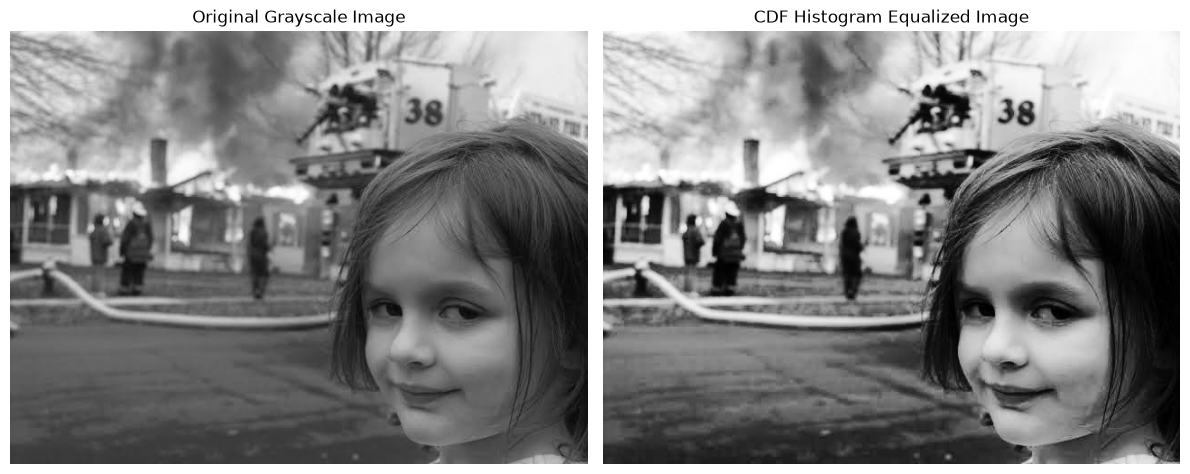

In [4]:
# Find the first non-zero CDF value
cdf_nonzero = cdf[cdf > 0]
cdf_min = cdf_nonzero[0]

# Apply CDF-based intensity mapping
if cdf[-1] > cdf_min:
    equalization_map = np.round(
        (cdf - cdf_min) / (cdf[-1] - cdf_min) * 255
    )
else:
    equalization_map = np.arange(256)

equalization_map = np.clip(equalization_map, 0, 255).astype(np.uint8)

# Apply the mapping to the grayscale image
equalized_image = equalization_map[gray_image]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("CDF Histogram Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### 5. Compare with OpenCV Histogram Equalization


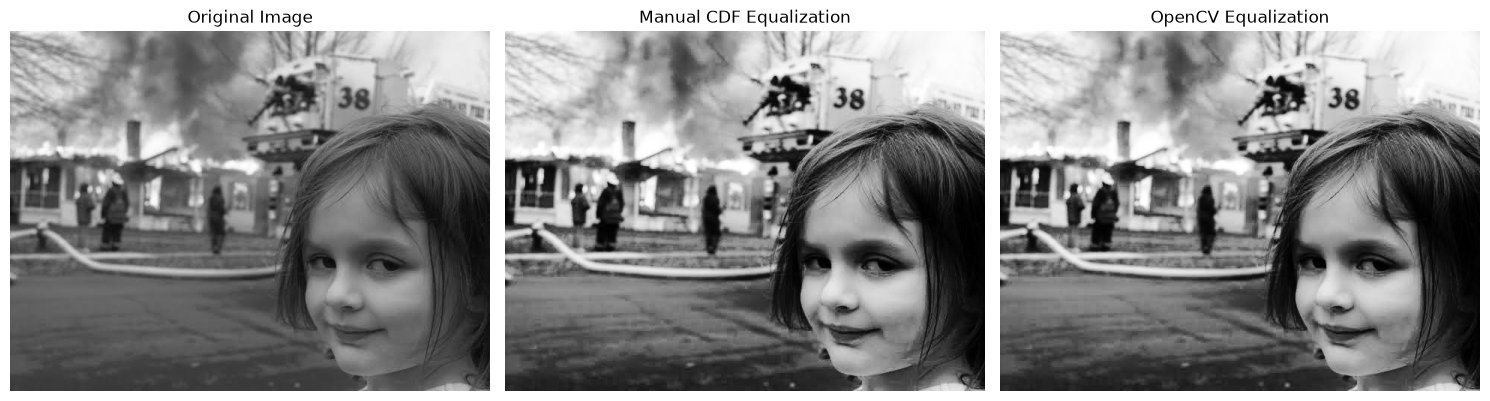

In [5]:
# Apply OpenCV histogram equalization
opencv_equalized = cv2.equalizeHist(gray_image)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Manual CDF Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(opencv_equalized, cmap="gray")
plt.title("OpenCV Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()

### 6. Compare Histograms Before and After Equalization


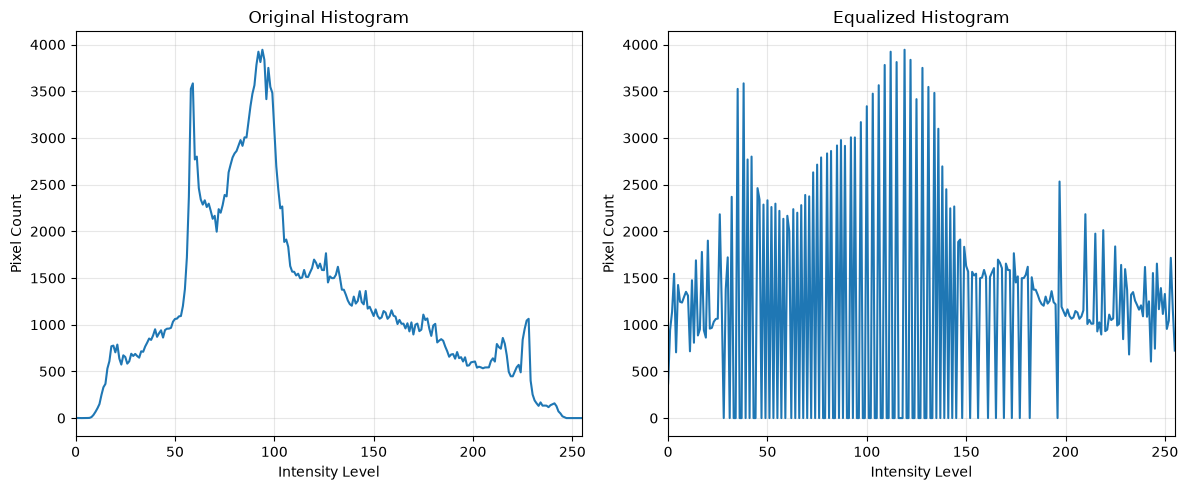

In [6]:
original_histogram = cv2.calcHist(
    [gray_image], [0], None, [256], [0, 256]
).flatten()

equalized_histogram = cv2.calcHist(
    [equalized_image], [0], None, [256], [0, 256]
).flatten()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(intensity_levels, original_histogram)
plt.title("Original Histogram")
plt.xlabel("Intensity Level")
plt.ylabel("Pixel Count")
plt.xlim(0, 255)
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(intensity_levels, equalized_histogram)
plt.title("Equalized Histogram")
plt.xlabel("Intensity Level")
plt.ylabel("Pixel Count")
plt.xlim(0, 255)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 7. Display the CDF-Based Transformation Curve


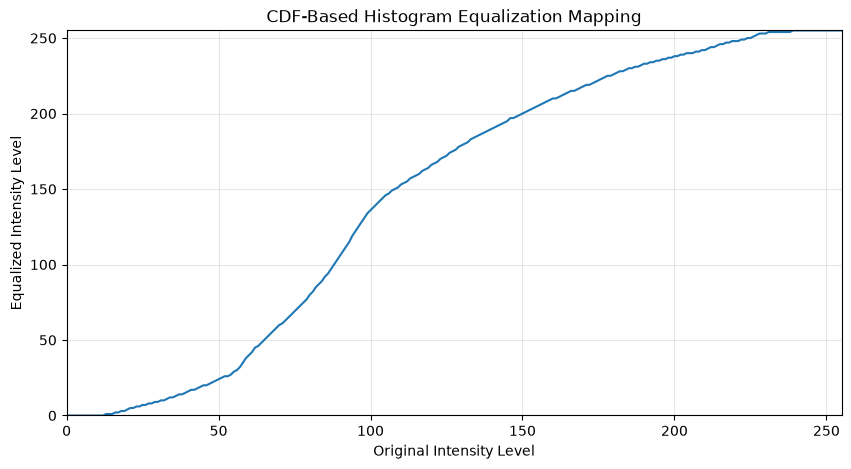

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(intensity_levels, equalization_map)
plt.title("CDF-Based Histogram Equalization Mapping")
plt.xlabel("Original Intensity Level")
plt.ylabel("Equalized Intensity Level")
plt.xlim(0, 255)
plt.ylim(0, 255)
plt.grid(True, alpha=0.3)

plt.show()

### 8. Verify the CDF and Equalization

In [8]:
equalized_pdf = equalized_histogram / equalized_image.size
equalized_cdf = np.cumsum(equalized_pdf)

print("Original image shape:", gray_image.shape)
print("Equalized image shape:", equalized_image.shape)
print("Original PDF sum:", np.sum(pdf))
print("Equalized PDF sum:", np.sum(equalized_pdf))
print("Final original CDF value:", cdf[-1])
print("Final equalized CDF value:", equalized_cdf[-1])

Original image shape: (480, 640)
Equalized image shape: (480, 640)
Original PDF sum: 1.0
Equalized PDF sum: 1.0
Final original CDF value: 1.0000007
Final equalized CDF value: 1.0000002
